## Load libraries

In [ ]:
import polars as pl
import os
from mpl_toolkits.mplot3d import Axes3D
from sklearn.preprocessing import StandardScaler
import polars as pl
pl.Config.set_tbl_rows(20)  # show up to 20 rows
import polars.selectors as cs
import seaborn as sns
sns.set_style("darkgrid")  # darkgrid
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import numpy as np
import pandas as pd

In [ ]:
def csv_to_parquet(path):
    # read CSV with Polars
    df = pl.read_csv(
        path,
        infer_schema_length=10000,
        ignore_errors=True
    )

    # get filename only (no folders)
    filename = os.path.basename(path)
    parquet_filename = filename.replace(".csv", ".parquet")

    # save in current working directory
    current_dir = os.getcwd()
    parquet_path = os.path.join(current_dir, parquet_filename)

    # write Parquet
    df.write_parquet(parquet_path, compression="snappy")

    print(f"Saved Parquet file to: {parquet_path}")

### Convert pandas to polar

In [ ]:
has_parquet = any(f.endswith(".parquet") for f in os.listdir("data"))
if has_parquet:
    print("Parquet file already exists in data folder")
else:
    print("No parquet file found. Converting CSV → Parquet...")
    csv_to_parquet("./data/raw_data/accepted_2007_to_2018Q4.csv")

### Read accepted_df

In [ ]:
# Never use CSV again
accepted_df = pl.read_parquet("./data/raw_data/accepted_2007_to_2018Q4.parquet")
accepted_df.head()

FileNotFoundError: The system cannot find the file specified. (os error 2): accepted_2007_to_2018Q4.parquet

In [ ]:
type_summary = (
    pl.DataFrame({
        "column": accepted_df.columns,
        "dtype":  [str(accepted_df[c].dtype) for c in accepted_df.columns],
        "nulls":  [accepted_df[c].is_null().sum() for c in accepted_df.columns],
        "null_pct": [round(accepted_df[c].is_null().sum() / len(accepted_df) * 100, 2) for c in accepted_df.columns],
    })
    .sort("dtype")
)

print(f"Dataset shape: f{len(accepted_df), len(accepted_df.columns)}")
print("\n----- Null Values Distribution -----")
print(type_summary)
print()
print("\n----- Datatype Counts -----")
print(
    type_summary
    .group_by("dtype")
    .agg(pl.count().alias("n_cols"))
    .sort("n_cols", descending=True)
)


Dataset shape: f(2260701, 151)

----- Null Values Distribution -----
shape: (151, 4)
┌───────────────────────────┬─────────┬─────────┬──────────┐
│ column                    ┆ dtype   ┆ nulls   ┆ null_pct │
│ ---                       ┆ ---     ┆ ---     ┆ ---      │
│ str                       ┆ str     ┆ i64     ┆ f64      │
╞═══════════════════════════╪═════════╪═════════╪══════════╡
│ loan_amnt                 ┆ Float64 ┆ 33      ┆ 0.0      │
│ funded_amnt               ┆ Float64 ┆ 33      ┆ 0.0      │
│ funded_amnt_inv           ┆ Float64 ┆ 33      ┆ 0.0      │
│ int_rate                  ┆ Float64 ┆ 33      ┆ 0.0      │
│ installment               ┆ Float64 ┆ 33      ┆ 0.0      │
│ annual_inc                ┆ Float64 ┆ 37      ┆ 0.0      │
│ dti                       ┆ Float64 ┆ 1744    ┆ 0.08     │
│ delinq_2yrs               ┆ Float64 ┆ 62      ┆ 0.0      │
│ fico_range_low            ┆ Float64 ┆ 33      ┆ 0.0      │
│ fico_range_high           ┆ Float64 ┆ 33      ┆ 0.0      │


/tmp/ipykernel_41393/1990453272.py:19: DeprecationWarning: `pl.count()` is deprecated. Please use `pl.len()` instead.
(Deprecated in version 0.20.5)
  .agg(pl.count().alias("n_cols"))


## Data understanding

In [ ]:
# Null in issue_d -> null in all columns
print(accepted_df.filter(accepted_df["issue_d"].is_null()))

# Remove rows with missing values in issue_d
accepted_df = accepted_df.drop_nulls(subset=["issue_d"])
print("Remove null in column issue_d done!")

shape: (33, 151)
┌──────┬───────────┬───────────┬────────────┬───┬────────────┬────────────┬────────────┬───────────┐
│ id   ┆ member_id ┆ loan_amnt ┆ funded_amn ┆ … ┆ settlement ┆ settlement ┆ settlement ┆ settlemen │
│ ---  ┆ ---       ┆ ---       ┆ t          ┆   ┆ _date      ┆ _amount    ┆ _percentag ┆ t_term    │
│ i64  ┆ str       ┆ f64       ┆ ---        ┆   ┆ ---        ┆ ---        ┆ e          ┆ ---       │
│      ┆           ┆           ┆ f64        ┆   ┆ str        ┆ f64        ┆ ---        ┆ f64       │
│      ┆           ┆           ┆            ┆   ┆            ┆            ┆ f64        ┆           │
╞══════╪═══════════╪═══════════╪════════════╪═══╪════════════╪════════════╪════════════╪═══════════╡
│ null ┆ null      ┆ null      ┆ null       ┆ … ┆ null       ┆ null       ┆ null       ┆ null      │
│ null ┆ null      ┆ null      ┆ null       ┆ … ┆ null       ┆ null       ┆ null       ┆ null      │
│ null ┆ null      ┆ null      ┆ null       ┆ … ┆ null       ┆ null       

In [ ]:
# Polar String display
pl.Config.set_fmt_str_lengths(1000)

# Loan Status Distribution
print(f'Total Rows    : {accepted_df.shape[0]:,}')
print(f'Total Columns : {accepted_df.shape[1]}')
issue_d_parsed = pd.to_datetime(accepted_df['issue_d'], format='%b-%Y', errors='coerce')
print(f'Date Range    : {issue_d_parsed.min().strftime("%b-%Y")} → {issue_d_parsed.max().strftime("%b-%Y")}')

print('\n----- Loan Status Distribution -----')
print(accepted_df['loan_status'].value_counts().sort("count", descending=True))

Total Rows    : 2,260,668
Total Columns : 151
Date Range    : Jun-2007 → Dec-2018

----- Loan Status Distribution -----
shape: (9, 2)
┌─────────────────────────────────────────────────────┬─────────┐
│ loan_status                                         ┆ count   │
│ ---                                                 ┆ ---     │
│ str                                                 ┆ u32     │
╞═════════════════════════════════════════════════════╪═════════╡
│ Fully Paid                                          ┆ 1076751 │
│ Current                                             ┆ 878317  │
│ Charged Off                                         ┆ 268559  │
│ Late (31-120 days)                                  ┆ 21467   │
│ In Grace Period                                     ┆ 8436    │
│ Late (16-30 days)                                   ┆ 4349    │
│ Does not meet the credit policy. Status:Fully Paid  ┆ 1988    │
│ Does not meet the credit policy. Status:Charged Off ┆ 761     │
│ Defaul

In [ ]:
accepted_df['loan_status'].value_counts()

loan_status,count
str,u32
"""Fully Paid""",1076751
"""Charged Off""",268559
"""Does not meet the credit policy. Status:Charged Off""",761
"""Default""",40
"""Does not meet the credit policy. Status:Fully Paid""",1988
"""Late (31-120 days)""",21467
"""In Grace Period""",8436
"""Late (16-30 days)""",4349
"""Current""",878317


## Data cleaning

In [ ]:
# select only known outcomes
accepted_df = accepted_df.filter(
    pl.col("loan_status").is_in(["Fully Paid", "Charged Off"])
)

# binary target: 1 = Charged Off (default), 0 = Fully Paid
accepted_df = accepted_df.with_columns(
    (pl.col("loan_status") == "Charged Off")
    .cast(pl.Int8)
    .alias("target")
)

# overall default rate
default_rate = accepted_df['target'].mean() * 100
print(f"Overall Default Rate: {default_rate:.2f}%")

Overall Default Rate: 19.96%


## Feature Selection

In [ ]:
def feat_corr(df: pl.DataFrame, features: list) -> None:
    """
    Computes and plots a correlation heatmap for all numeric features.

    Args:
        df       : Polars DataFrame
        features : list of feature column names
    """

    # Select only numeric columns
    numeric_df = df.select(features).select(cs.numeric()).to_pandas()
    non_numeric = [c for c in features if c not in numeric_df.columns]

    print(f"Numeric features   : {len(numeric_df.columns)}")
    print(f"Non-numeric features)  : {non_numeric}")

    # Compute correlation matrix
    corr_matrix = numeric_df.corr()

    # Plot
    n = len(corr_matrix)
    fig, ax = plt.subplots(figsize=(n * 0.7 + 2, n * 0.6 + 2))

    mask = np.triu(np.ones_like(corr_matrix, dtype=bool))   # upper triangle mask

    sns.heatmap(
        corr_matrix,
        mask=mask,
        annot=True,
        fmt=".2f",
        annot_kws={"size": 7},
        cmap="RdBu_r",
        center=0,
        vmin=-1, vmax=1,
        linewidths=0.4,
        linecolor="white",
        square=True,
        cbar_kws={"shrink": 0.6, "label": "Pearson r"},
        ax=ax
    )

    ax.set_title("Feature Correlation Matrix (numeric only)",
                 fontsize=14, fontweight="bold", pad=15)
    ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha="right", fontsize=8)
    ax.set_yticklabels(ax.get_yticklabels(), rotation=0, fontsize=8)

    plt.tight_layout()
    plt.savefig("correlation_matrix.png", dpi=150, bbox_inches="tight")
    plt.show()

    # Top 10 correlated pairs (excluding self-correlation)
    corr_pairs = (
        corr_matrix
        .unstack()
        .reset_index()
        .rename(columns={"level_0": "feature_1", "level_1": "feature_2", 0: "correlation"})
        .query("feature_1 != feature_2")                        # drop self
        .assign(abs_corr=lambda x: x["correlation"].abs())
        .drop_duplicates(subset=["abs_corr"])                   # drop mirror pairs
        .sort_values("abs_corr", ascending=False)
        .head(10)
    )

    print("\n  Top 10 most correlated pairs:")
    print(corr_pairs[["feature_1", "feature_2", "correlation"]].to_string(index=False))

In [ ]:
# Polars missing value analysis
missing_df = (
    pl.DataFrame({
        "column": accepted_df.columns,
        "null_count": [accepted_df[col].is_null().sum() for col in accepted_df.columns]
    })
    .with_columns(
        (pl.col("null_count") / len(accepted_df) * 100).alias("null_pct")
    )
    .filter(pl.col("null_pct") > 0)
    .sort("null_pct", descending=True)
)

# Summary statistics
over_50 = missing_df.filter(pl.col("null_pct") >  50)
between_20 = missing_df.filter(
                (pl.col("null_pct") >  20) &
                (pl.col("null_pct") <= 50)
             )

print(f"Number of features with > 50% missing: {over_50.height}")
print(f"Features with 20–50% missing: {between_20.height}")
print(f"Selected columns which is < 20% missing values:")
print(accepted_df.select([col for col in accepted_df.columns
                          if (col not in over_50["column"].to_list())
                          & (col not in between_20["column"].to_list())]).columns)

Number of features with > 50% missing: 58
Features with 20–50% missing: 0
Selected columns which is < 20% missing values:
['id', 'loan_amnt', 'funded_amnt', 'funded_amnt_inv', 'term', 'int_rate', 'installment', 'grade', 'sub_grade', 'emp_title', 'emp_length', 'home_ownership', 'annual_inc', 'verification_status', 'issue_d', 'loan_status', 'pymnt_plan', 'url', 'purpose', 'title', 'zip_code', 'addr_state', 'dti', 'delinq_2yrs', 'earliest_cr_line', 'fico_range_low', 'fico_range_high', 'inq_last_6mths', 'open_acc', 'pub_rec', 'revol_bal', 'revol_util', 'total_acc', 'initial_list_status', 'out_prncp', 'out_prncp_inv', 'total_pymnt', 'total_pymnt_inv', 'total_rec_prncp', 'total_rec_int', 'total_rec_late_fee', 'recoveries', 'collection_recovery_fee', 'last_pymnt_d', 'last_pymnt_amnt', 'last_credit_pull_d', 'last_fico_range_high', 'last_fico_range_low', 'collections_12_mths_ex_med', 'policy_code', 'application_type', 'acc_now_delinq', 'tot_coll_amt', 'tot_cur_bal', 'total_rev_hi_lim', 'acc_ope

### Missing value percentage

In [ ]:
missing_df

column,null_count,null_pct
str,i64,f64
"""member_id""",1345310,100.0
"""next_pymnt_d""",1345310,100.0
"""orig_projected_additional_accrued_interest""",1341551,99.720585
"""hardship_type""",1339556,99.572292
"""hardship_reason""",1339556,99.572292
"""hardship_status""",1339556,99.572292
"""deferral_term""",1339556,99.572292
"""hardship_amount""",1339556,99.572292
"""hardship_start_date""",1339556,99.572292


### Build heatmap - corralted features

Selected 34 features + target
   Shape: (1345310, 35)
  Numeric features   : 27
  Non-numeric features)  : ['term', 'grade', 'sub_grade', 'purpose', 'emp_length', 'home_ownership', 'earliest_cr_line', 'verification_status']


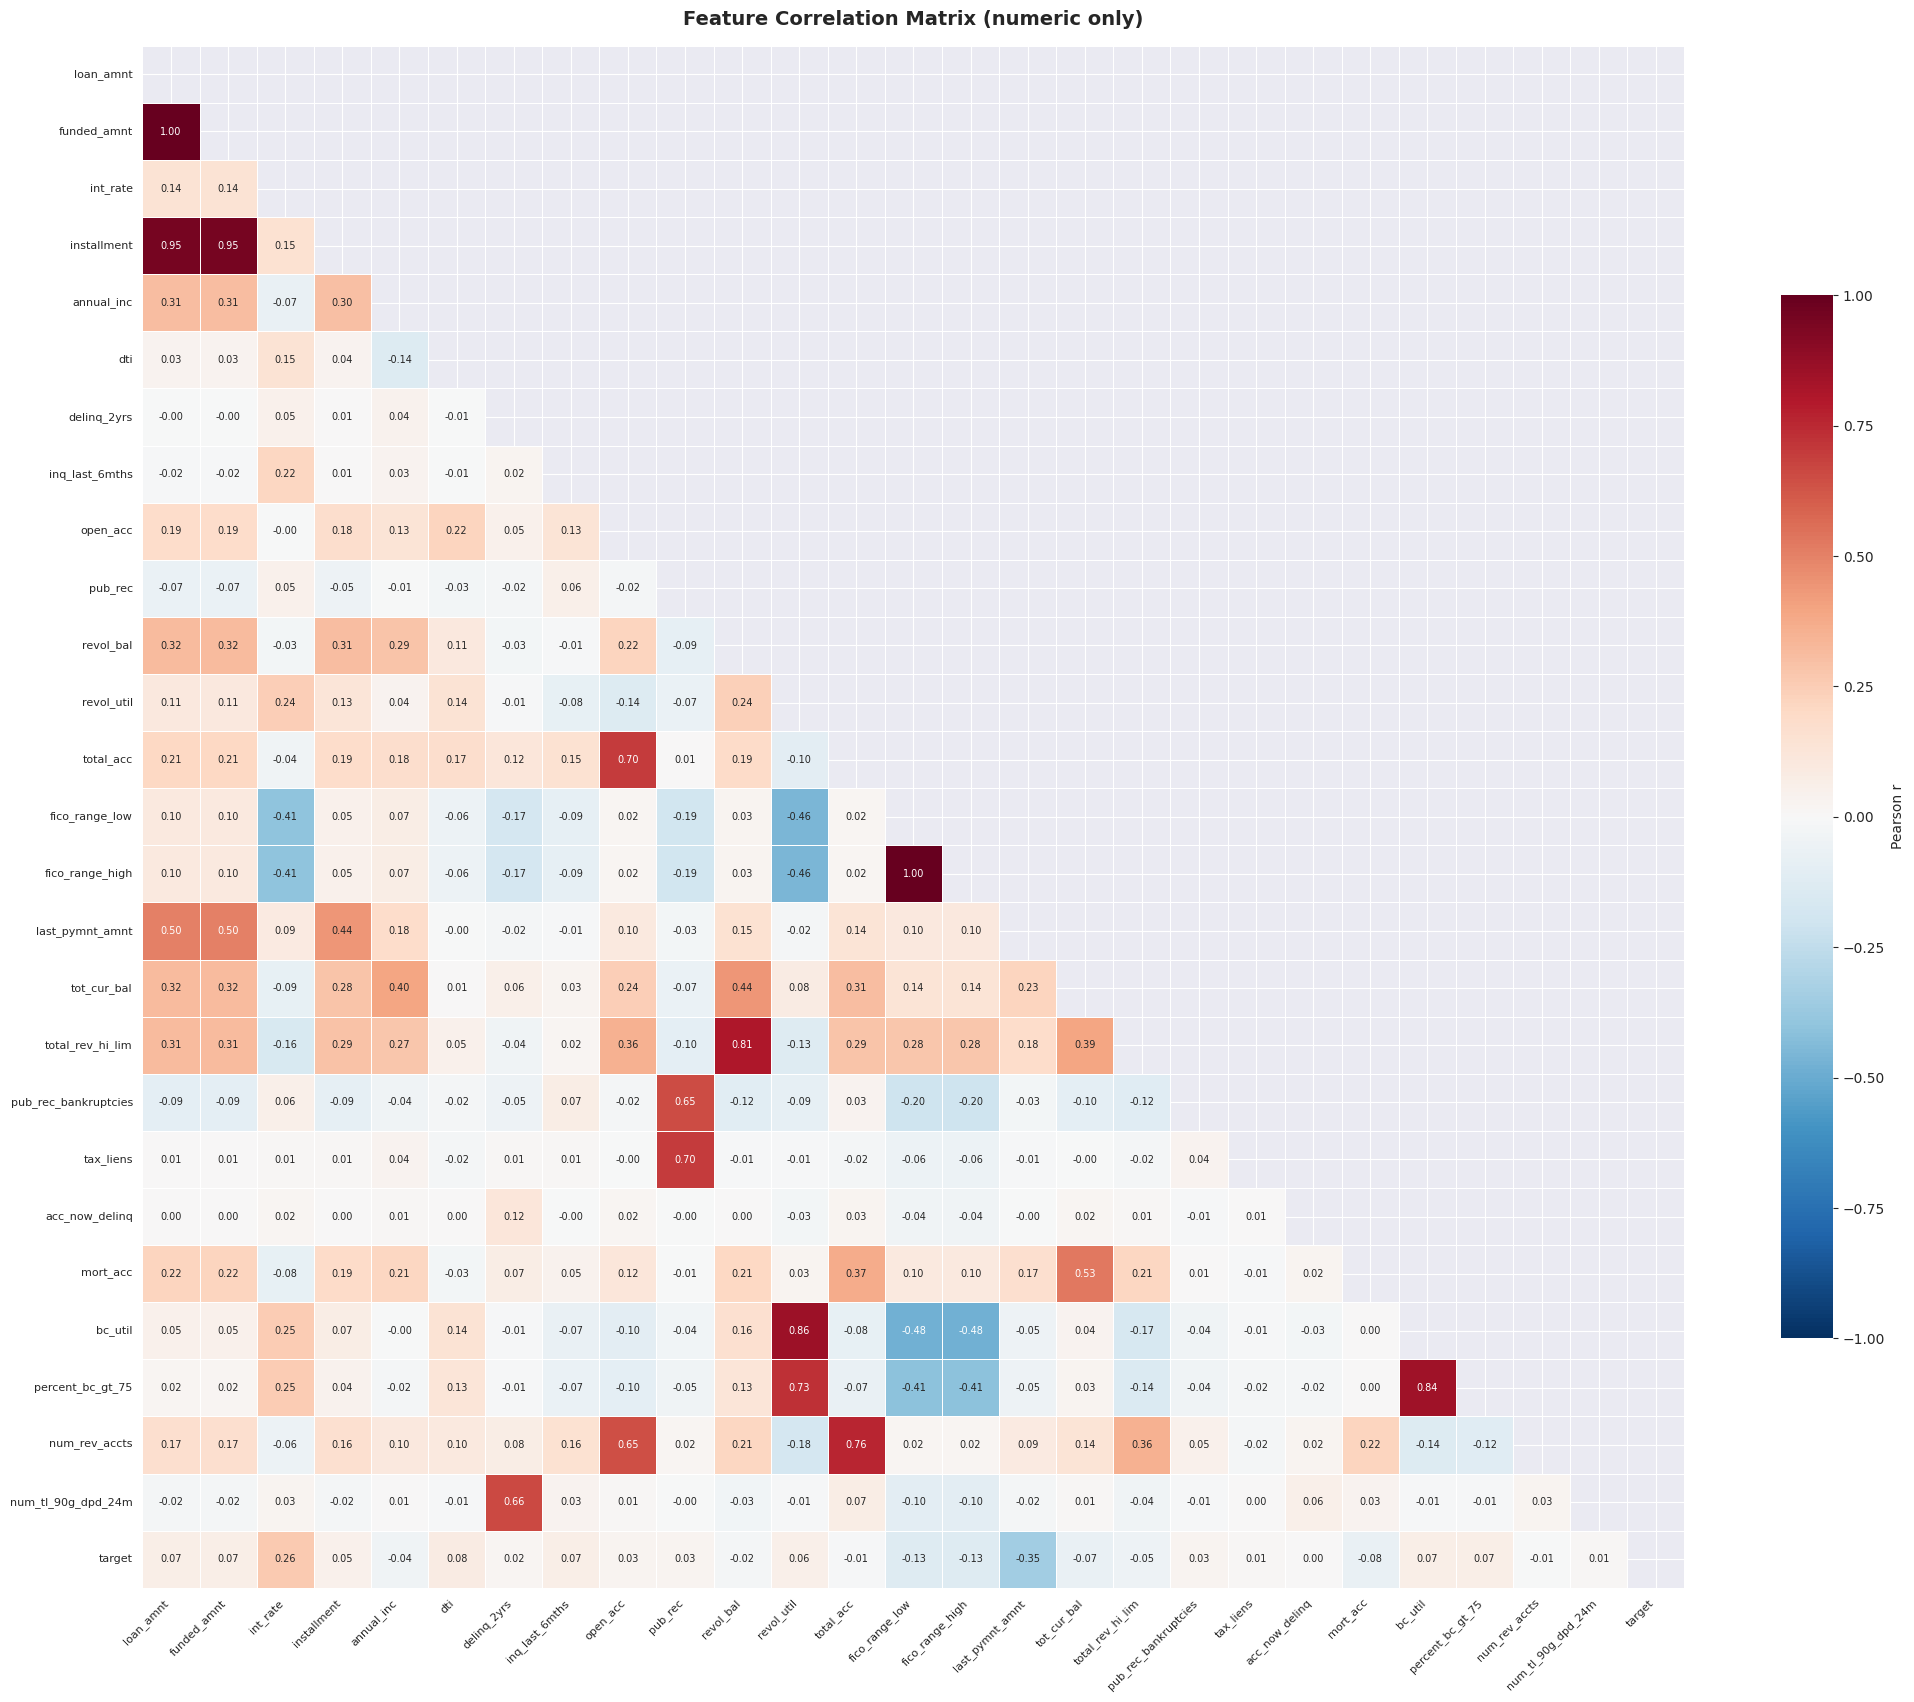


  Top 10 most correlated pairs:
     feature_1        feature_2  correlation
fico_range_low  fico_range_high     1.000000
     loan_amnt      funded_amnt     0.999562
   funded_amnt      installment     0.954053
     loan_amnt      installment     0.953401
    revol_util          bc_util     0.855022
       bc_util percent_bc_gt_75     0.844702
     revol_bal total_rev_hi_lim     0.810244
     total_acc    num_rev_accts     0.762554
    revol_util percent_bc_gt_75     0.726870
      open_acc        total_acc     0.701325


In [ ]:
FEATURES = [
    # Loan info
    'loan_amnt', 'funded_amnt', 'term', 'int_rate', 'installment',
    'grade', 'sub_grade', 'purpose',
    # Borrower financials
    'annual_inc', 'dti', 'delinq_2yrs', 'inq_last_6mths',
    'open_acc', 'pub_rec', 'revol_bal', 'revol_util', 'total_acc',
    # Employment
    'emp_length', 'home_ownership',
    # Credit history
    'earliest_cr_line', 'fico_range_low', 'fico_range_high',
    'last_pymnt_amnt', 'tot_cur_bal', 'total_rev_hi_lim',
    # Risk
    'verification_status', 'pub_rec_bankruptcies', 'tax_liens',
    'acc_now_delinq', 'mort_acc', 'bc_util', 'percent_bc_gt_75',
    'num_rev_accts', 'num_tl_90g_dpd_24m',
    # Target
    'target'
]

# Filter to only existing columns (safety check)
available = [col for col in FEATURES if col in accepted_df.columns]
df = accepted_df.select(available)
print(f"Selected {len(available) - 1} features + target")
print(f"   Shape: {df.shape}")

# Columns not in dataset
missing_cols = [col for col in FEATURES if col not in accepted_df.columns]
if missing_cols:
    print(f" Warning — not found in df: {missing_cols}")

# Feature correlation
feat_corr(df, FEATURES)

### Final features selection

In [ ]:
FEATURES_FINAL = [
    # Loan info
    'loan_amnt', 'term', 'int_rate',
    'grade', 'sub_grade', 'purpose',
    # Borrower financials
    'annual_inc', 'dti', 'delinq_2yrs', 'inq_last_6mths',
    'open_acc', 'pub_rec', 'revol_bal', 'revol_util',
    # Employment
    'emp_length', 'home_ownership',
    # Credit history
    'earliest_cr_line', 'fico_score_low',
    'last_pymnt_amnt', 'tot_cur_bal',
    # Risk
    'verification_status', 'pub_rec_bankruptcies', 'tax_liens',
    'acc_now_delinq', 'mort_acc', 'bc_util', 'percent_bc_gt_75',
    'num_rev_accts', 'num_tl_90g_dpd_24m',
    # Target
    'target'
]

In [ ]:
clean_df = accepted_df.select(FEATURES_FINAL)
print(clean_df.schema)           # dtypes
print(clean_df.shape)            # (rows, cols)
print(clean_df.null_count())

#  Separate features and target
X = clean_df.drop("target")
y = clean_df.select("target")
print(f"Final feature matrix : {X.shape}")
print(f" Target shape   : {y.shape}")
print(f" Default rate   : {y['target'].mean()*100:.2f}%")

Schema({'loan_amnt': Float64, 'term': String, 'int_rate': Float64, 'grade': String, 'sub_grade': String, 'purpose': String, 'annual_inc': Float64, 'dti': Float64, 'delinq_2yrs': Float64, 'inq_last_6mths': Float64, 'open_acc': Float64, 'pub_rec': Float64, 'revol_bal': Float64, 'revol_util': Float64, 'emp_length': String, 'home_ownership': String, 'earliest_cr_line': String, 'fico_score_avg': Float64, 'last_pymnt_amnt': Float64, 'tot_cur_bal': Float64, 'verification_status': String, 'pub_rec_bankruptcies': Float64, 'tax_liens': Float64, 'acc_now_delinq': Float64, 'mort_acc': Float64, 'bc_util': Float64, 'percent_bc_gt_75': Float64, 'num_rev_accts': Float64, 'num_tl_90g_dpd_24m': Float64, 'target': Int8})
(1345310, 30)
shape: (1, 30)
┌───────────┬──────┬──────────┬───────┬───┬───────────────┬───────────────┬───────────────┬────────┐
│ loan_amnt ┆ term ┆ int_rate ┆ grade ┆ … ┆ percent_bc_gt ┆ num_rev_accts ┆ num_tl_90g_dp ┆ target │
│ ---       ┆ ---  ┆ ---      ┆ ---   ┆   ┆ _75          

### emp_length
emp_length: Employment length in years. Possible values are between 0 and 10 where 0 means less than one year and 10 means ten or more years.
$\rightarrow$ Replace $(<1, 0)$, $(10+, 10)$, and remove null rows

In [ ]:
print(clean_df["emp_length"].value_counts().sort("count", descending=True))

shape: (12, 2)
┌────────────┬────────┐
│ emp_length ┆ count  │
│ ---        ┆ ---    │
│ str        ┆ u32    │
╞════════════╪════════╡
│ 10+ years  ┆ 442199 │
│ 2 years    ┆ 121743 │
│ < 1 year   ┆ 108061 │
│ 3 years    ┆ 107597 │
│ 1 year     ┆ 88494  │
│ 5 years    ┆ 84154  │
│ 4 years    ┆ 80556  │
│ null       ┆ 78511  │
│ 6 years    ┆ 62733  │
│ 8 years    ┆ 60701  │
│ 7 years    ┆ 59624  │
│ 9 years    ┆ 50937  │
└────────────┴────────┘


In [ ]:
# transform emp_lenth columns
clean_df = clean_df.with_columns(
    pl.col("emp_length")
    .str.replace("10\\+ years", "10 years")
    .str.replace("< 1 year", "0 years")
    .str.extract(r"(\d+)")
    .cast(pl.Int8)
    .alias("emp_length")
)

# remove null values
clean_df = clean_df.drop_nulls(subset=["emp_length"])

print(clean_df["emp_length"].value_counts().sort("emp_length"))

shape: (11, 2)
┌────────────┬────────┐
│ emp_length ┆ count  │
│ ---        ┆ ---    │
│ i8         ┆ u32    │
╞════════════╪════════╡
│ 0          ┆ 108061 │
│ 1          ┆ 88494  │
│ 2          ┆ 121743 │
│ 3          ┆ 107597 │
│ 4          ┆ 80556  │
│ 5          ┆ 84154  │
│ 6          ┆ 62733  │
│ 7          ┆ 59624  │
│ 8          ┆ 60701  │
│ 9          ┆ 50937  │
│ 10         ┆ 442199 │
└────────────┴────────┘


### home_ownership
home_ownership: The home ownership status provided by the borrower.

Values: RENT, OWN, MORTGAGE, OTHER

In [ ]:
# drop nulls and replace none/any to other
clean_df = (clean_df.drop_nulls(subset=["home_ownership"])
                  .with_columns(pl.col("home_ownership").replace({"NONE": "OTHER", "ANY": "OTHER"})))

print(clean_df["home_ownership"].value_counts().sort("count", descending=True))

shape: (4, 2)
┌────────────────┬────────┐
│ home_ownership ┆ count  │
│ ---            ┆ ---    │
│ str            ┆ u32    │
╞════════════════╪════════╡
│ MORTGAGE       ┆ 629291 │
│ RENT           ┆ 507862 │
│ OWN            ┆ 129192 │
│ OTHER          ┆ 454    │
└────────────────┴────────┘


### verification_status

verification_status: Indicates if income was verified by LendingClub.

Values: Verified, Source Verified, Not Verified

In [ ]:
clean_df = clean_df.drop_nulls(subset=["verification_status"])
print(clean_df["verification_status"].value_counts().sort("count", descending=True))

### pub_rec_bankcruptcies

In [ ]:
clean_df = clean_df.drop_nulls(subset=["pub_rec_bankruptcies"])

print(clean_df["pub_rec_bankruptcies"].value_counts().sort("count", descending=True))

bktc_default = (
    clean_df
    .group_by("pub_rec_bankruptcies")
    .agg([
        pl.col("target").sum().alias("charged_off"),
        pl.len().alias("total")
    ])
    .with_columns(
        (pl.col("charged_off") / pl.col("total") * 100).alias("chargeoff_rate")
    )
    .sort("chargeoff_rate", descending=True)
    .to_pandas()
)

shape: (12, 2)
┌──────────────────────┬─────────┐
│ pub_rec_bankruptcies ┆ count   │
│ ---                  ┆ ---     │
│ f64                  ┆ u32     │
╞══════════════════════╪═════════╡
│ 0.0                  ┆ 1114316 │
│ 1.0                  ┆ 142623  │
│ 2.0                  ┆ 7139    │
│ 3.0                  ┆ 1461    │
│ 4.0                  ┆ 361     │
│ 5.0                  ┆ 133     │
│ 6.0                  ┆ 42      │
│ 7.0                  ┆ 14      │
│ 8.0                  ┆ 8       │
│ 9.0                  ┆ 3       │
│ 11.0                 ┆ 1       │
│ 12.0                 ┆ 1       │
└──────────────────────┴─────────┘


### purpose
purpose: A category provided by the borrower for the loan request.

Values: debt_consolidation, credit_card, home_improvement, etc.

In [ ]:
clean_df = clean_df.drop_nulls(subset=["purpose"])

print(clean_df["purpose"].value_counts().sort("count", descending=True))

purpose_default = (
    clean_df
    .group_by("purpose")
    .agg([
        pl.col("target").sum().alias("charged_off"),
        pl.len().alias("total")
    ])
    .with_columns(
        (pl.col("charged_off") / pl.col("total") * 100).alias("chargeoff_rate")
    )
    .sort("chargeoff_rate", descending=True)
    .to_pandas()
)

shape: (14, 2)
┌────────────────────┬────────┐
│ purpose            ┆ count  │
│ ---                ┆ ---    │
│ str                ┆ u32    │
╞════════════════════╪════════╡
│ debt_consolidation ┆ 737280 │
│ credit_card        ┆ 277310 │
│ home_improvement   ┆ 81205  │
│ other              ┆ 72144  │
│ major_purchase     ┆ 27754  │
│ small_business     ┆ 14924  │
│ medical            ┆ 14244  │
│ car                ┆ 13763  │
│ moving             ┆ 8875   │
│ vacation           ┆ 8366   │
│ house              ┆ 6818   │
│ wedding            ┆ 2243   │
│ renewable_energy   ┆ 876    │
│ educational        ┆ 300    │
└────────────────────┴────────┘


### annual_inc

annual_inc: The self-reported annual income provided by the borrower.

shape: (9, 2)
┌────────────┬──────────────┐
│ statistic  ┆ value        │
│ ---        ┆ ---          │
│ str        ┆ f64          │
╞════════════╪══════════════╡
│ count      ┆ 1.266102e6   │
│ null_count ┆ 0.0          │
│ mean       ┆ 77904.067011 │
│ std        ┆ 71068.992023 │
│ min        ┆ 0.0          │
│ 25%        ┆ 48000.0      │
│ 50%        ┆ 65000.0      │
│ 75%        ┆ 92555.0      │
│ max        ┆ 1.09992e7    │
└────────────┴──────────────┘


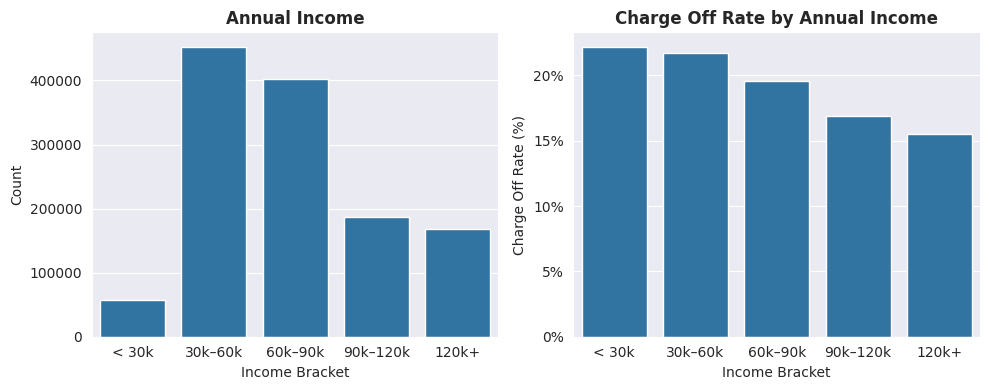

In [ ]:
clean_df = clean_df.drop_nulls(subset=["annual_inc"])

print(clean_df["annual_inc"].describe())

# Bin into brackets
clean_df = clean_df.with_columns(
    pl.when(pl.col("annual_inc") < 30000).then(pl.lit("< 30k"))
    .when(pl.col("annual_inc") < 60000).then(pl.lit("30k–60k"))
    .when(pl.col("annual_inc") < 90000).then(pl.lit("60k–90k"))
    .when(pl.col("annual_inc") < 120000).then(pl.lit("90k–120k"))
    .otherwise(pl.lit("120k+"))
    .alias("income_bracket")
)

## Save cleaned file

In [ ]:
clean_df.write_parquet("./data/processed_data/processed_accepted_df.parquet")